# 2. házi feladat — Gépi tanulás: hiperparaméter-vadászat a Telco Customer Churn adatsoron

**Adatsor:** [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (IBM mintaadat, Kaggle) —
7043 telekommunikációs ügyfél, a kérdés: **lemondja-e az ügyfél a szolgáltatást** (`Churn` = Yes/No)?

**Felépítés** (az órai „helyes sorrend” szerint: hipotézis → EDA → lineáris baseline → ML-modellek):
1. Hipotézis
2. Adatbetöltés és tisztítás
3. Feltáró elemzés (EDA)
4. Baseline: „mindenki marad” modell + logisztikus regresszió
5. Modellösszehasonlítás alapbeállításokkal (mint a `demo.ipynb` 9. szekciója)
6. Hiperparaméter-vadászat: Random Forest és Gradient Boosting
7. Komplexitás-görbe: tanuló vs. teszt pontosság a fa mélységének függvényében
8. Melyik változó számít? (feature importance)
9. Bónusz: K legközelebbi szomszéd és a dimenzió-átok
10. Értékelés

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix

plt.rcParams["figure.figsize"] = (7, 4)
RANDOM_STATE = 7

## 1. Hipotézis

*Mielőtt egy sort is kódolnék:* azt várom, hogy a lemondás valószínűségét főleg az határozza meg, **mennyire „elkötelezett” az ügyfél**:

- a **havi szerződéses** ügyfelek sokkal gyakrabban mondanak le, mint az 1-2 éves szerződésesek (nincs „büntetés” a felmondásért),
- az **új ügyfelek** (kicsi `tenure`, azaz kevés hónapja ügyfél) gyakrabban mondanak le, mint a régiek,
- a **magasabb havidíjat** fizetők gyakrabban mondanak le (érzékenyebbek az árra).

## 2. Adatbetöltés és tisztítás

Két dolgot kell rendbe tenni:
- a `TotalCharges` (eddig összesen kifizetett díj) **szövegként** jön, és 11 sorban üres szóköz van benne — ezek mind `tenure = 0` (most csatlakozott) ügyfelek, tehát valójában még 0 Ft-ot fizettek;
- a `customerID` csak azonosító, nincs magyarázó ereje → eldobjuk.

In [2]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Hiányzó TotalCharges:", df["TotalCharges"].isna().sum(),
      "| ezek tenure értékei:", df.loc[df["TotalCharges"].isna(), "tenure"].unique())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df = df.drop(columns="customerID")
df["Churn"] = (df["Churn"] == "Yes").astype(int)

df.head()

(7043, 21)
Hiányzó TotalCharges: 11 | ezek tenure értékei: [0]


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 3. Feltáró elemzés (EDA)

Az EDA célja (órai jegyzet): **meggyőzni egy laikust**, hogy a hipotézisnek van értelme.

### 3a. Mennyire kiegyensúlyozatlan a célváltozó?

In [3]:
churn_rate = df["Churn"].mean()
print(f"Lemondási arány: {churn_rate:.1%}  ({df['Churn'].sum()} lemondó / {len(df)} ügyfél)")

Lemondási arány: 26.5%  (1869 lemondó / 7043 ügyfél)


Kb. minden negyedik ügyfél mond le. Ez fontos: egy modell, ami **mindenkire azt mondja, hogy marad**,
már kb. 73%-os pontosságot ér el — tehát az accuracy önmagában félrevezető lehet, ezért a **precision / recall / F1** értékeket is nézni fogjuk.

### 3b. Lemondási arány a hipotézisben szereplő változók szerint

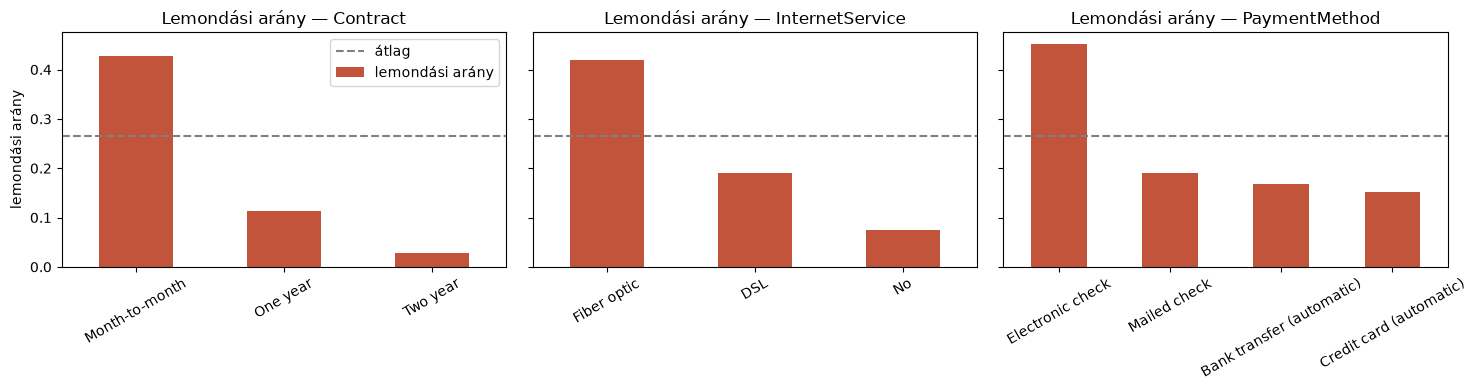

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    rates = df.groupby(col)["Churn"].mean().sort_values(ascending=False)
    rates.plot(kind="bar", ax=ax, color="#c1543a", label="lemondási arány")
    ax.axhline(churn_rate, color="gray", linestyle="--", label="átlag")
    ax.set_title(f"Lemondási arány — {col}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("lemondási arány")
axes[0].legend()
plt.tight_layout()
plt.show()

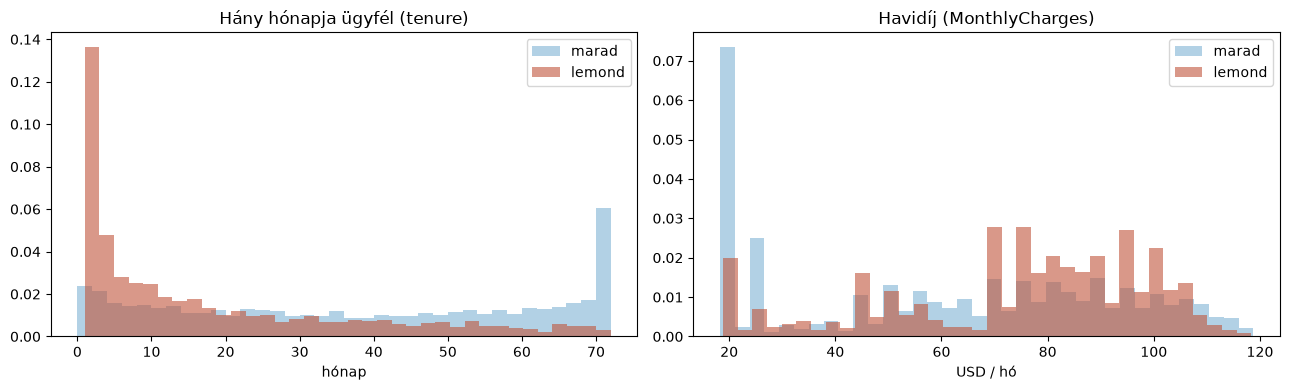

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for churn, label, color in [(0, "marad", "#7fb3d5"), (1, "lemond", "#c1543a")]:
    subset = df[df["Churn"] == churn]
    axes[0].hist(subset["tenure"], bins=36, alpha=0.6, density=True, label=label, color=color)
    axes[1].hist(subset["MonthlyCharges"], bins=36, alpha=0.6, density=True, label=label, color=color)
axes[0].set_title("Hány hónapja ügyfél (tenure)")
axes[0].set_xlabel("hónap")
axes[1].set_title("Havidíj (MonthlyCharges)")
axes[1].set_xlabel("USD / hó")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

### 3c. Rejtett ismétlés a változók között

A `TotalCharges` lényegében `tenure × MonthlyCharges` — vagyis nem hoz sok új információt, a két másik változó **összefonódva** tartalmazza.
Ez lineáris modellnél multikollinearitást okoz (az együtthatók nehezen értelmezhetők), a fa-alapú modelleket kevésbé zavarja.

In [6]:
corr = np.corrcoef(df["TotalCharges"], df["tenure"] * df["MonthlyCharges"])[0, 1]
print(f"Korreláció: TotalCharges vs. tenure × MonthlyCharges = {corr:.3f}")

Korreláció: TotalCharges vs. tenure × MonthlyCharges = 1.000


### EDA összegzés

Az ábrák nagyrészt igazolják a hipotézist. A legerősebb jel a **szerződés típusa**: a havi szerződéses ügyfelek kb. 43%-a mond le,
az egyéveseknek kb. 11%-a, a kétéveseknek alig 3%-a. A `tenure` hisztogramon jól látszik, hogy a lemondók túlnyomó része
**az első néhány hónapban** távozik, a 70 hónapnál régebbi ügyfelek közül viszont szinte senki. A havidíjnál is igaz a hipotézis:
a legolcsóbb (~20 USD/hó) csomagot fizetők szinte mind maradnak, a lemondók inkább a 70-105 USD/hó sávban sűrűsödnek.
Két dolgot nem vártam előre: az **optikai internettel** rendelkezők (~42%) és az **elektronikus csekkel** fizetők (~45%) is kiugróan
gyakran mondanak le — az előbbi valószínűleg az árral függ össze (ez a drágább szolgáltatás), az utóbbi az elkötelezettséggel
(aki automatikus utalással fizet, annak a lemondás egy plusz lépés).

## 4. Előkészítés és baseline

- kategorikus változók → dummy (0/1) oszlopok (`drop_first=True`, mint az órán),
- **ugyanaz a felosztás, mint a `demo.ipynb`-ben**: 25% teszt, `random_state=7`, `stratify=y` (hogy a lemondók aránya mindkét halmazban azonos legyen),
- a skálázót **csak a tanuló halmazon** illesztjük — különben a teszthalmaz információja „beszivárogna” (data leakage).

In [7]:
X = pd.get_dummies(df.drop(columns="Churn"), drop_first=True).astype(float)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Tanuló:", X_train.shape, "| Teszt:", X_test.shape, "| feature-ök száma:", X.shape[1])

Tanuló: (5282, 30) | Teszt: (1761, 30) | feature-ök száma: 30


In [8]:
def evaluate(model, name):
    """Illeszt, majd visszaadja a tanuló és teszt pontosságot, a kettő különbségét és a teszt F1-et."""
    model.fit(X_train_scaled, y_train)
    train_acc = accuracy_score(y_train, model.predict(X_train_scaled))
    test_pred = model.predict(X_test_scaled)
    test_acc = accuracy_score(y_test, test_pred)
    return {
        "modell": name,
        "tanuló pontosság": train_acc,
        "teszt pontosság": test_acc,
        "különbség (overfitting jele)": train_acc - test_acc,
        "teszt F1": f1_score(y_test, test_pred, zero_division=0),
    }

In [9]:
baseline_models = {
    "„Mindenki marad” (többségi osztály)": DummyClassifier(strategy="most_frequent"),
    "Logisztikus regresszió": LogisticRegression(max_iter=1000),
}
baseline_df = pd.DataFrame([evaluate(m, n) for n, m in baseline_models.items()]).set_index("modell")
baseline_df.round(3)

,tanuló pontosság,teszt pontosság,különbség (overfitting jele),teszt F1
modell,,,,
„Mindenki marad” (többségi osztály),0.735,0.735,-0.000,0.000
Logisztikus regresszió,0.809,0.808,0.001,0.601


A „mindenki marad” modell F1-e 0: egyetlen lemondót sem talál meg, mégis ~73%-os a pontossága. **Ezt kell mindenképp megverni.**

A logisztikus regresszió konfúziós mátrixa és metrikái (ugyanúgy, mint az órán a Titanicon):

In [10]:
logreg = baseline_models["Logisztikus regresszió"]
baseline_pred = logreg.predict(X_test_scaled)
tn, fp, fn, tp = confusion_matrix(y_test, baseline_pred).ravel()
print(f"TP={tp} FP={fp} TN={tn} FN={fn}")
print(f"accuracy={accuracy_score(y_test, baseline_pred):.3f}  "
      f"precision={precision_score(y_test, baseline_pred):.3f}  "
      f"recall={recall_score(y_test, baseline_pred):.3f}  "
      f"f1={f1_score(y_test, baseline_pred):.3f}")

TP=255 FP=126 TN=1168 FN=212
accuracy=0.808  precision=0.669  recall=0.546  f1=0.601


## 5. Modellösszehasonlítás alapbeállításokkal

Ugyanaz a 6 modell, mint a `demo.ipynb` 9. szekciójában — de itt **valóban sklearn-alapbeállításokkal** (a demóban a fa és a Random Forest már kapott `max_depth`-et),
és a teszt mellett a **tanuló pontosságot is** nézzük.

In [11]:
default_models = {
    "Logisztikus regresszió": LogisticRegression(max_iter=1000),
    "SVM": SVC(),
    "Döntési fa": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Neurális háló": MLPClassifier(hidden_layer_sizes=(16, 16), max_iter=500, random_state=RANDOM_STATE),
}
default_df = (
    pd.DataFrame([evaluate(m, n) for n, m in default_models.items()])
    .set_index("modell")
    .sort_values("teszt pontosság", ascending=False)
)
default_df.round(3)

,tanuló pontosság,teszt pontosság,különbség (overfitting jele),teszt F1
modell,,,,
Gradient Boosting,0.826,0.811,0.015,0.605
Random Forest,0.998,0.810,0.188,0.591
SVM,0.815,0.809,0.005,0.587
Logisztikus regresszió,0.809,0.808,0.001,0.601
Neurális háló,0.840,0.793,0.047,0.581
Döntési fa,0.998,0.730,0.268,0.512


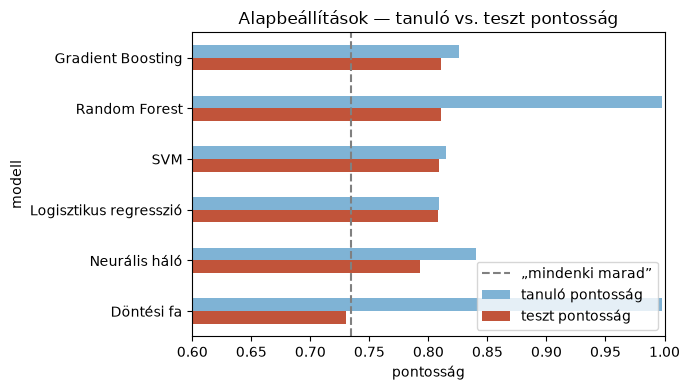

In [12]:
ax = default_df[["tanuló pontosság", "teszt pontosság"]].plot(kind="barh", color=["#7fb3d5", "#c1543a"])
ax.axvline(baseline_df.loc["„Mindenki marad” (többségi osztály)", "teszt pontosság"],
           color="gray", linestyle="--", label="„mindenki marad”")
ax.set_xlim(0.6, 1.0)
ax.set_xlabel("pontosság")
ax.set_title("Alapbeállítások — tanuló vs. teszt pontosság")
ax.invert_yaxis()
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 6. Hiperparaméter-vadászat

A két választott modell: **Random Forest** és **Gradient Boosting** — mindkettő fákból épít együttest, de ellentétes stratégiával
(párhuzamos, független fák átlaga vs. egymás hibáit javító, egymás utáni fák), így jól összevethető, hogyan reagálnak ugyanarra a „komplexitás-csavarra”.

### 6a. Random Forest

| Hiperparaméter | Mit szabályoz |
|---|---|
| `max_depth` | milyen mély lehet egy-egy fa (komplexitás-csavar) |
| `n_estimators` | hány fát átlagolunk |
| `min_samples_leaf` | legalább hány ügyfélnek kell egy levélben lennie (minél nagyobb, annál „óvatosabb” a fa) |

In [13]:
rf_configs = [
    dict(n_estimators=100, max_depth=None),                       # alapbeállítás
    dict(n_estimators=200, max_depth=3),
    dict(n_estimators=200, max_depth=6),
    dict(n_estimators=200, max_depth=10),
    dict(n_estimators=500, max_depth=8, min_samples_leaf=5),
]
rf_df = pd.DataFrame([
    evaluate(RandomForestClassifier(random_state=RANDOM_STATE, **params), str(params))
    for params in rf_configs
]).set_index("modell")
rf_df.round(3)

,tanuló pontosság,teszt pontosság,különbség (overfitting jele),teszt F1
modell,,,,
"{'n_estimators': 100, 'max_depth': None}",0.998,0.810,0.188,0.591
"{'n_estimators': 200, 'max_depth': 3}",0.777,0.790,-0.014,0.421
"{'n_estimators': 200, 'max_depth': 6}",0.805,0.813,-0.008,0.580
"{'n_estimators': 200, 'max_depth': 10}",0.865,0.822,0.044,0.618
"{'n_estimators': 500, 'max_depth': 8, 'min_samples_leaf': 5}",0.821,0.820,0.001,0.615


### 6b. Gradient Boosting

| Hiperparaméter | Mit szabályoz |
|---|---|
| `n_estimators` | hány boosting-kört futtatunk (komplexitás-csavar) |
| `learning_rate` | mekkora lépést tesz minden kör a maradék hiba felé (mint a gradient descentnél) |
| `max_depth` | milyen mélyek az egyes (gyenge) fák |

In [14]:
gb_configs = [
    dict(n_estimators=100, learning_rate=0.1, max_depth=3),       # alapbeállítás
    dict(n_estimators=300, learning_rate=0.03, max_depth=3),
    dict(n_estimators=200, learning_rate=0.05, max_depth=2),
    dict(n_estimators=500, learning_rate=0.1, max_depth=3),
    dict(n_estimators=500, learning_rate=0.3, max_depth=8),
]
gb_df = pd.DataFrame([
    evaluate(GradientBoostingClassifier(random_state=RANDOM_STATE, **params), str(params))
    for params in gb_configs
]).set_index("modell")
gb_df.round(3)

,tanuló pontosság,teszt pontosság,különbség (overfitting jele),teszt F1
modell,,,,
"{'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3}",0.826,0.811,0.015,0.605
"{'n_estimators': 300, 'learning_rate': 0.03, 'max_depth': 3}",0.823,0.812,0.011,0.605
"{'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 2}",0.811,0.818,-0.007,0.613
"{'n_estimators': 500, 'learning_rate': 0.1, 'max_depth': 3}",0.882,0.804,0.078,0.600
"{'n_estimators': 500, 'learning_rate': 0.3, 'max_depth': 8}",0.998,0.790,0.208,0.572


### 6c. Ellenőrzés kereszt-validációval

Egyetlen teszthalmazon (1761 ügyfél) mért 0,5-1%-os különbség **lehet puszta szerencse is**. Ráadásul ha a teszthalmazon
választjuk ki a legjobb beállítást, a teszthalmaz már nem teljesen „független” mérce.
Ezért a legjobb beállításokat a **tanuló halmazon 5-szörös kereszt-validációval** is összevetjük a baseline-nal.

In [15]:
best_rf_params = rf_configs[int(np.argmax(rf_df["teszt pontosság"].values))]
best_gb_params = gb_configs[int(np.argmax(gb_df["teszt pontosság"].values))]
print("Legjobb RF beállítás (teszt alapján):", best_rf_params)
print("Legjobb GB beállítás (teszt alapján):", best_gb_params)

cv_models = {
    "Logisztikus regresszió": LogisticRegression(max_iter=1000),
    "Random Forest (legjobb)": RandomForestClassifier(random_state=RANDOM_STATE, **best_rf_params),
    "Gradient Boosting (legjobb)": GradientBoostingClassifier(random_state=RANDOM_STATE, **best_gb_params),
}
for name, model in cv_models.items():
    scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring="accuracy")
    print(f"{name:30s} CV pontosság: {scores.mean():.3f} ± {scores.std():.3f}")

Legjobb RF beállítás (teszt alapján): {'n_estimators': 200, 'max_depth': 10}
Legjobb GB beállítás (teszt alapján): {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 2}
Logisztikus regresszió         CV pontosság: 0.802 ± 0.005


Random Forest (legjobb)        CV pontosság: 0.794 ± 0.008


Gradient Boosting (legjobb)    CV pontosság: 0.799 ± 0.008


## 7. Komplexitás-görbe: tanuló vs. teszt pontosság a fa mélysége szerint

Ugyanaz a kép, mint az órán a polinom fokszámánál: a tanuló pontosság monoton nő, a teszt pontosság egy pont után **romlani kezd**.

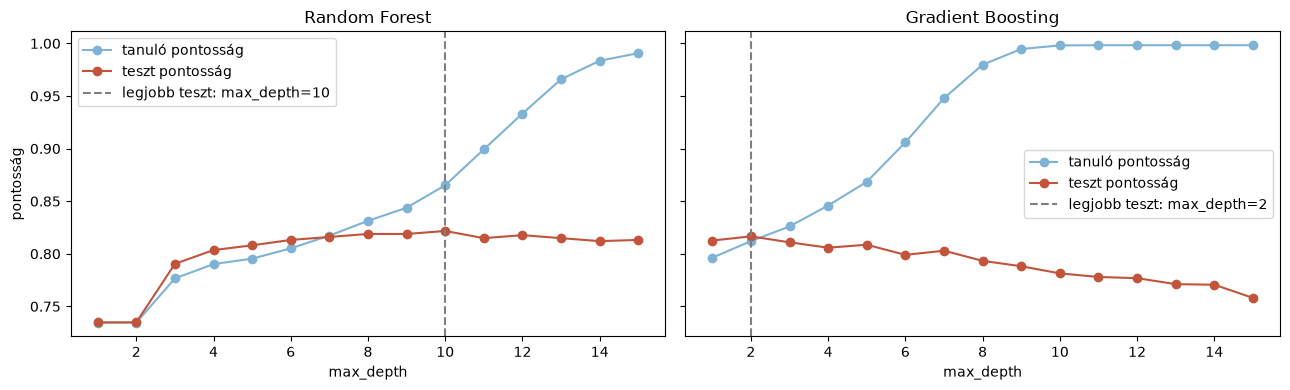

In [16]:
depths = list(range(1, 16))
curves = {"Random Forest": ([], []), "Gradient Boosting": ([], [])}
for d in depths:
    for name, model in [
        ("Random Forest", RandomForestClassifier(n_estimators=200, max_depth=d, random_state=RANDOM_STATE)),
        ("Gradient Boosting", GradientBoostingClassifier(max_depth=d, random_state=RANDOM_STATE)),
    ]:
        model.fit(X_train_scaled, y_train)
        curves[name][0].append(accuracy_score(y_train, model.predict(X_train_scaled)))
        curves[name][1].append(accuracy_score(y_test, model.predict(X_test_scaled)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (name, (train_acc, test_acc)) in zip(axes, curves.items()):
    ax.plot(depths, train_acc, marker="o", color="#7fb3d5", label="tanuló pontosság")
    ax.plot(depths, test_acc, marker="o", color="#c1543a", label="teszt pontosság")
    best = depths[int(np.argmax(test_acc))]
    ax.axvline(best, color="gray", linestyle="--", label=f"legjobb teszt: max_depth={best}")
    ax.set_title(name)
    ax.set_xlabel("max_depth")
    ax.legend()
axes[0].set_ylabel("pontosság")
plt.tight_layout()
plt.show()

## 8. Melyik változó számít?

Az órai jegyzet szerint ellenőrizni kell, hogy a **magyarázó változók valóban magyaráznak-e** — vagyis a modell tényleg azokra támaszkodik-e, amiket az EDA és a hipotézis alapján vártunk.
A legjobb Gradient Boosting modell feature importance-a (mennyivel csökkentette az adott változó a hibát a fák osztásaiban), és összevetésként a logisztikus regresszió együtthatói
(skálázott adaton, így összemérhetők; pozitív = növeli a lemondás esélyét).

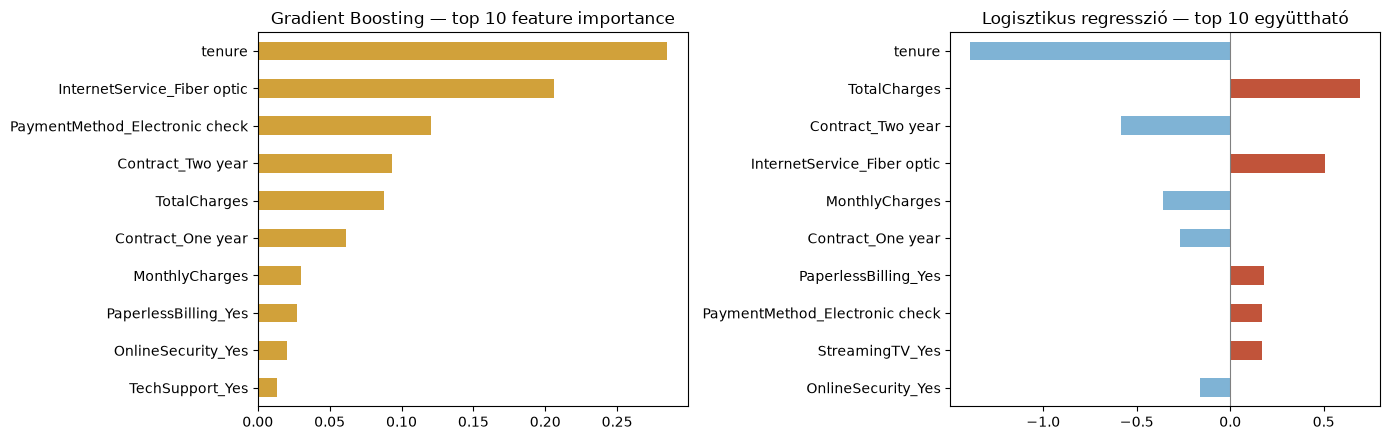

In [17]:
best_gb = GradientBoostingClassifier(random_state=RANDOM_STATE, **best_gb_params).fit(X_train_scaled, y_train)
importance = pd.Series(best_gb.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
coefs = pd.Series(logreg.coef_[0], index=X.columns)
top_coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
importance.plot(kind="barh", ax=axes[0], color="#d1a13a")
axes[0].set_title("Gradient Boosting — top 10 feature importance")
axes[0].invert_yaxis()
top_coefs.plot(kind="barh", ax=axes[1], color=["#c1543a" if c > 0 else "#7fb3d5" for c in top_coefs])
axes[1].set_title("Logisztikus regresszió — top 10 együttható")
axes[1].axvline(0, color="gray", linewidth=0.8)
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

**A magyarázó változók valóban magyaráznak:** mindkét modellben a `tenure` a legfontosabb, és előkelő helyen van a kétéves szerződés,
az optikai internet és az elektronikus csekk — pontosan azok, amelyek az EDA-ban is kiugrottak. A logisztikus regresszióban a
`MonthlyCharges` együtthatója viszont **negatív**, holott az EDA szerint a magasabb havidíj több lemondással jár. Ez a 3c pontban
látott összefonódás következménye: a `TotalCharges` ≈ `tenure × MonthlyCharges`, így a modell „szétosztja” a hatást a három változó
között, és az egyes együtthatók külön-külön már nem értelmezhetők. Ezért kell óvatosan bánni a lineáris modell együtthatóival, ha
a változók erősen korrelálnak.

## 9. Bónusz: K legközelebbi szomszéd (KNN)

A KNN egy új ügyfelet a hozzá **legközelebb eső** `k` tanuló ügyfél többségi szavazata alapján sorol be.
`k = 1` a legkomplexebb (minden egyes tanulópont saját „területet” kap — a tanuló pontosság közel 100%), nagy `k` a legegyszerűbb.

In [18]:
knn_df = pd.DataFrame([
    evaluate(KNeighborsClassifier(n_neighbors=k), f"k = {k}") for k in [1, 3, 5, 15, 51, 151]
]).set_index("modell")
knn_df.round(3)

,tanuló pontosság,teszt pontosság,különbség (overfitting jele),teszt F1
modell,,,,
k = 1,0.998,0.734,0.265,0.511
k = 3,0.857,0.763,0.093,0.545
k = 5,0.833,0.761,0.072,0.541
k = 15,0.806,0.793,0.013,0.601
k = 51,0.796,0.802,-0.007,0.619
k = 151,0.786,0.797,-0.011,0.596


**Dimenzió-átok:** a dummy-kódolás után kb. 30 dimenzióban dolgozunk. Magas dimenzióban a pontok közti távolságok „összemosódnak” —
a legközelebbi és a legtávolabbi szomszéd szinte ugyanolyan messze van —, így a „szomszéd” fogalma, amire a KNN épül, egyre kevésbé jelent valódi hasonlóságot.
A fa-alapú modelleket ez kevésbé érinti, mert egyszerre mindig csak **egy** változó mentén vágnak.

**Mit mutat a táblázat?** A `k = 1` tankönyvi overfitting: a tanuló pontosság 0,998, a teszt csak 0,734 — rosszabb, mint a
„mindenki marad” modell. Ahogy `k` nő, a döntési határ simul, a szakadék eltűnik, és `k = 51`-nél a teszt pontosság (0,802) eléri
a logisztikus regresszió szintjét; `k = 151`-nél már enyhén romlik (alulillesztés felé megy). A `k` itt ugyanaz a komplexitás-csavar,
mint a fánál a `max_depth`, csak **fordított irányban**: kis `k` = bonyolult modell.

**Miért nem jobb ennél?** A KNN minden változót egyformán súlyoz a távolságban — a nemet vagy a `StreamingTV`-t ugyanannyira, mint a
szerződés típusát —, így a lényegtelen dimenziók zajt visznek a távolságba. A ~30 dimenzió nagy része ráadásul 0/1 dummy,
ezért sok ügyfél pár egyforma távolságra van egymástól. A fák ezzel szemben maguk választják ki, melyik változó mentén vágjanak,
így a lényegtelen dimenziókat egyszerűen figyelmen kívül hagyják.

## 10. Értékelés (4-6 mondat)

A Random Forestnél a **`max_depth=10`** (200 fa, teszt: 0,822), a Gradient Boostingnál a **sekély, 2 mélységű fákból lassan
(`learning_rate=0.05`) építkező** változat (0,818) volt a legjobb — mindkettő a komplexitás „középső” tartományában van: elég rugalmas
a fő mintázatokhoz (szerződés, tenure, internet típusa), de nem annyira, hogy a zajt is megtanulja. A GB-nél azért elég a 2-es mélység,
mert ott a sok egymás utáni fa együtt adja a rugalmasságot, míg az RF fái egymástól függetlenek, ezért egyenként mélyebbnek kell lenniük.
Egyértelmű **overfittinget** a korlátozás nélküli fáknál láttam: az alapbeállítású döntési fa és Random Forest tanuló pontossága 0,998,
a teszté 0,730, ill. 0,810, a `max_depth=8, learning_rate=0.3` Gradient Boosting pedig 0,998 vs. 0,790 — a komplexitás-görbén a GB
teszt pontossága 2-es mélység felett folyamatosan romlik. A legfontosabb tanulság viszont, hogy a hangolás a teszthalmazon is csak
kb. 1 százalékpontot hozott a logisztikus regresszióhoz (0,808) képest, **5-szörös kereszt-validációval pedig a logisztikus regresszió
lett a legjobb** (0,802 vs. 0,799 és 0,794) — vagyis a teszthalmazon mért kis előny valószínűleg a felosztás szerencséjéből jön.
Ebben az adatban a fontos összefüggések nagyrészt egyirányúak és additívak (pl. minél régebbi az ügyfél, annál kisebb a lemondás esélye),
így a fák rugalmassága nem hoz sokat; a KISS-elv szerint itt a jól értelmezhető logisztikus regressziót választanám.